# Delinquency Roll-Rate Forecasting with Sequence Models

Servicers, collections teams and securitisation analysts all track how loans move between "current", "30 days late", "60 days late" and worse. The classic tool assumes only this month's bucket matters, but a loan that just cured from 60 days late behaves very differently from one that has always paid. This notebook tests how much a loan's payment history adds, with sequence models that read it directly, in calm years and in the 2008–2010 housing crisis.

**What it does.** It forecasts how mortgages move between delinquency states (current, 30, 60, 90+ days, paid off) one and six months ahead, on Fannie Mae loans originated in 2005–08 and Freddie Mac loans originated in 2018–23.

It compares the classic first-order Markov roll-rate matrix, a Markov model with covariates (multinomial logit), and an LSTM and a small Transformer that read each loan's last 12 months of payment history.

The forecasts are aggregated to the pool level, which is what a securitisation surveillance desk or a servicer's collections plan needs, and every model is put through a regime test: trained on data to 2007, asked to forecast the crisis.

**Data.** Fannie Mae Single-Family Loan Performance data (2005–2008 acquisitions) and the Freddie Mac Single-Family Loan-Level Dataset (vintages 2018–2023), monthly performance to March 2026.

**Methods.** Monthly state sequences with forbearance flags, empirical transition matrices and their powers, multinomial logit, and LSTM and Transformer encoders (PyTorch) with class-balanced sampling and importance weights.

One-step and six-step forecasts are scored out of time on log-loss, accuracy for delinquent loans, roll-rate calibration and pool-level state-share errors.

**Key output.** Roll-rate matrices, the accuracy of each model by starting state, how much payment history adds beyond the current state, and pool delinquency forecasts against what happened, out of time in 2024–25 and in the crisis.

## 1. Roll rates and the Markov assumption

Collections teams, servicers and ABS surveillance all work with **roll rates**: the share of loans in one delinquency bucket this month that move to another next month (current → 30, 30 → 60, 60 → 90+, and the cure rates back to current). Stacked in a matrix $P$, a first-order **Markov chain** forecasts the pool $k$ months ahead as $\pi_{t+k}=\pi_t P^k$.

The Markov assumption is that the current bucket is all that matters. Payment history says otherwise: a loan that cured last month from 60 days late is far more likely to fall back than one that has always been current, and a loan in a forbearance plan behaves differently from one that simply stopped paying.

Sequence models (LSTM, Transformer) read the whole recent path and can learn that path dependence; the question is whether it is worth their opacity.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 5
LOAN_SAMPLE = 6  # 1 in 6 loans
WINDOW = 12  # months of history the sequence models read
H = 6  # long forecast horizon (months)
# training anchors up to mid-2023 (their t+6 target falls before 2024)
TRAIN_LAST_ANCHOR = 202306
TEST_FIRST, TEST_LAST = 202401, 202509
# crisis test: train on anchors to Dec 2007, test July 2008 - June 2010
CRISIS_TRAIN_LAST, CRISIS_TEST = 200712, (200807, 201006)
# keep 8% of anchors whose whole window is current (weights restore the
# population)
CLEAN_KEEP = 0.08
STATES = ["current", "30 days", "60 days", "90+ days", "paid off"]
torch.manual_seed(SEED)
np.random.seed(SEED)

print(
    f"torch {torch.__version__} · duckdb {duckdb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

torch 2.14.1+cu130 · duckdb 1.5.6 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Freddie Mac Single-Family Loan-Level Dataset (sample files)
# Download manually (free registration, non-commercial licence):
# https://freddiemac.embs.com/FLoan/Data/download.php
# → "Sample Dataset" → sample_YYYY.zip, saved in data/freddie_mac/ at the repo
# root.
# The files are licensed and are never committed: data/ is in .gitignore.
import zipfile


def find_shared_data(name):
    """
    Find data/<name> in this project's folder or any folder above it, up to the
    repo root (works with sub-folders).
    """
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
        if (d / ".git").exists():
            break
    return None


FREDDIE_DIR = find_shared_data("freddie_mac")
if FREDDIE_DIR is None or not list(FREDDIE_DIR.glob("sample_*.zip")):
    raise FileNotFoundError(
        "Put the Freddie Mac sample_YYYY.zip files in FIN/data/freddie_mac/"
        " (see the link above)."
    )
FM_TXT = DATA_DIR / "freddie_txt"
FM_TXT.mkdir(exist_ok=True)
for z in sorted(FREDDIE_DIR.glob("sample_*.zip")):
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))

ORIG_COLS = [
    "credit_score",
    "first_pay_date",
    "first_time_buyer",
    "maturity_date",
    "msa",
    "mi_pct",
    "n_units",
    "occupancy",
    "cltv",
    "dti",
    "orig_upb",
    "ltv",
    "orig_rate",
    "channel",
    "ppm_flag",
    "amort_type",
    "state",
    "prop_type",
    "zip3",
    "loan_id",
    "purpose",
    "orig_term",
    "n_borrowers",
    "seller_servicer",
    "super_conforming",
    "pre_relief_id",
    "program",
    "relief_refi",
    "valuation_method",
    "io_flag",
    "mi_cancel",
]
PERF_COLS = {
    0: "loan_id",
    1: "period",
    2: "upb",
    3: "dq",
    4: "age",
    5: "months_left",
    7: "mod_flag",
    8: "zb_code",
    9: "zb_date",
    10: "rate",
    21: "actual_loss",
    25: "eltv",
    26: "zb_upb",
    29: "assistance",
}


def freddie_con():
    con = duckdb.connect(
        str(DATA_DIR / "freddie.duckdb")
    )  # tables on disk, not in the notebook's memory
    con.execute("SET enable_progress_bar = false")
    con.execute("SET memory_limit = '2GB'")
    orig_sel = ", ".join(
        f"column{i:02d} AS {c}" for i, c in enumerate(ORIG_COLS)
    )
    con.execute(
        f"""CREATE OR REPLACE VIEW orig AS SELECT {orig_sel}
                    FROM read_csv('{(FM_TXT / "sample_orig_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    perf_sel = ", ".join(f"column{i:02d} AS {c}" for i, c in PERF_COLS.items())
    con.execute(
        f"""CREATE OR REPLACE VIEW perf AS SELECT {perf_sel}
                    FROM read_csv('{(FM_TXT / "sample_perf_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    return con


# --- Fannie Mae Single-Family Loan Performance data, 2005-2008 acquisitions
# Download manually (free registration): https://capitalmarkets.fanniemae.com
# → Single-Family Loan Performance Data → quarterly files 2005Q1 ... 2008Q4,
# saved as data/fannie_mae/2005Q1.zip ... at the repo root. The first run
# builds a sample in the Freddie Mac sample format (12,500 loans per quarter,
# 50,000 per vintage, monthly history) in data/fannie_mae/sample/ and reuses
# it afterwards. The files are licensed and are never committed.
import random


def _ym(s):
    return s[2:] + s[:2] if len(s) == 6 else ""


def _num(s, d=0.0):
    try:
        return float(s)
    except ValueError:
        return d


def fannie_quarter_to_sample(zip_path, yy, q, out_dir, keep=12_500,
                             share=0.08):
    """Filter one quarterly file (loan id mod 1000 < 80), draw `keep` loans
    and append them to sample_orig_20yy.txt / sample_perf_20yy.txt."""
    with zipfile.ZipFile(zip_path) as zf:
        name = zf.namelist()[0]
        lines = []
        with zf.open(name) as f:
            for raw in f:
                line = raw.decode("latin-1")
                lid = line.split("|", 3)[1]
                if int(lid) % 1000 < share * 1000:
                    lines.append(line)
    ids, seen = [], set()
    for line in lines:
        i = line.split("|", 3)[1]
        if i not in seen:
            seen.add(i)
            ids.append(i)
    random.seed(int(f"20{yy}{q}"))
    chosen = set(random.sample(ids, min(keep, len(ids))))
    new_id = {i: f"F{yy}Q{q}{k:07d}" for k, i in enumerate(sorted(chosen))}
    fo = open(out_dir / f"sample_orig_20{yy}.txt", "a")
    fp = open(out_dir / f"sample_perf_20{yy}.txt", "a")
    done, last_age = set(), {}
    for line in lines:
        x = line.rstrip("\n").split("|")
        lid = x[1]
        if lid not in chosen:
            continue
        p = lambda k: x[k - 1] if k - 1 < len(x) else ""
        nid = new_id[lid]
        if lid not in done:
            done.add(lid)
            purpose = {"P": "P", "C": "C", "R": "N"}.get(p(27), "9")
            o = [p(24) or "9999", _ym(p(15)),
                 p(26) if p(26) in ("Y", "N") else "9", _ym(p(19)), p(32),
                 p(34) or "0", p(29), p(30), p(21) or "999", p(23) or "999",
                 str(int(_num(p(10)))), p(20) or "999", p(8), p(4) or "9",
                 p(36) or "N", p(35) or "FRM", p(31), p(28), p(33), nid,
                 purpose, p(13), p(22) or "99", (p(5) or "OTHER").upper(),
                 p(87) or "N", "", p(79), p(103) or "N", p(86) or "9",
                 p(37) or "N", p(43) or "9999"]
            fo.write("|".join(o) + "\n")
        per, zb, upb = _ym(p(3)), p(44), _num(p(12))
        age = int(_num(p(16), -1))
        if age < 0:
            age = last_age.get(lid, -1) + 1
        last_age[lid] = age
        if upb == 0 and not zb:         # masked in the first months
            upb = _num(p(11)) or _num(p(10))
        loss = ""
        if p(59) or p(60) or p(62):     # disposition: Freddie-style loss
            zbu, rate = _num(p(46)), _num(p(9)) or _num(p(8))
            lp, zd = _ym(p(51)), _ym(p(45)) or per
            gap = ((int(zd[:4]) - int(lp[:4])) * 12 + int(zd[4:])
                   - int(lp[4:])) if lp and zd else 0
            dai = zbu * rate / 1200 * max(gap - 1, 0)
            costs = sum(_num(p(k)) for k in (54, 55, 56, 57, 58))
            proceeds = sum(_num(p(k)) for k in (59, 60, 61, 62))
            loss = f"{proceeds - zbu - costs - dai:.2f}"
        r = [""] * 35
        r[0], r[1], r[2] = nid, per, f"{0.0 if zb else upb:.2f}"
        r[3] = "" if p(40) == "XX" else p(40)
        r[4], r[5] = str(age), p(18)
        r[7] = "Y" if p(42) == "Y" else ""
        r[8], r[9], r[10] = zb, _ym(p(45)), p(9) or p(8)
        r[11], r[12] = p(63) or "0.00", _ym(p(51))
        r[21], r[26], r[29] = loss, (p(46) if zb else ""), p(102)
        r[31] = f"{_num(p(110)) or (0.0 if zb else upb):.2f}"
        r[33] = (p(6) or "OTHER").upper()
        fp.write("|".join(r) + "\n")
    fo.close()
    fp.close()


def fannie_sample_zips():
    src = find_shared_data("fannie_mae")
    if src is None:
        return []
    out = src / "sample"
    if not list(out.glob("sample_*.zip")):
        quarters = sorted(src.glob("20??Q?.zip"))
        if not quarters:
            return []
        out.mkdir(exist_ok=True)
        tmp = DATA_DIR / "fannie_build"
        tmp.mkdir(exist_ok=True)
        for z in quarters:              # about 1-2 minutes per quarter
            print("sampling", z.name)
            fannie_quarter_to_sample(z, z.stem[2:4], z.stem[-1], tmp)
        for y in sorted({z.stem[:4] for z in quarters}):
            with zipfile.ZipFile(out / f"sample_{y}.zip", "w",
                                 zipfile.ZIP_DEFLATED) as zf:
                for kind in ["orig", "perf"]:
                    zf.write(tmp / f"sample_{kind}_{y}.txt",
                             f"sample_{kind}_{y}.txt")
    return sorted(out.glob("sample_*.zip"))


for z in fannie_sample_zips():
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))


## 3. Monthly state sequences

Each loan-month is put in one of five states: current, 30, 60 or 90+ days delinquent (90+ includes later stages and REO), or paid off (any zero-balance termination, absorbing). A second channel records whether the loan is in a forbearance or other borrower-assistance plan that month.

In [3]:
con = freddie_con()
seq = con.execute(f"""
SELECT loan_id, CAST(period AS INT) AS per, CAST(age AS INT) AS age,
       CASE WHEN zb_code IS NOT NULL THEN 4
            WHEN dq = '00' THEN 0 WHEN dq = '01' THEN 1 WHEN dq = '02' THEN 2 ELSE 3 END AS state,
       (COALESCE(assistance, '') <> '')::INT AS assist
FROM perf WHERE hash(loan_id) % {LOAN_SAMPLE} = 0
ORDER BY loan_id, per""").df()
seq = seq.drop_duplicates(["loan_id", "per"])
first_term = seq[seq["state"] == 4].groupby("loan_id")["per"].min()
# stop after the first termination
seq = seq[~(seq["per"] > seq["loan_id"].map(first_term).fillna(999999))]
static = (
    con.execute(
        f"""
SELECT loan_id, TRY_CAST(credit_score AS DOUBLE) AS fico, TRY_CAST(cltv AS DOUBLE) AS cltv, TRY_CAST(dti AS DOUBLE) AS dti,
       TRY_CAST(orig_rate AS DOUBLE) AS rate FROM orig WHERE hash(loan_id) % {LOAN_SAMPLE} = 0"""
    )
    .df()
    .set_index("loan_id")
)
for c, lo, hi, fill in [
    ("fico", 300, 850, 750),
    ("cltv", 1, 200, 80),
    ("dti", 1, 65, 36),
]:
    static[c] = static[c].where(static[c].between(lo, hi)).fillna(fill)
static = (static - static.mean()) / static.std()
share = (
    seq.groupby("per")["state"]
    .value_counts(normalize=True)
    .unstack()
    .fillna(0)
    .reindex(columns=range(5), fill_value=0)
)
print(
    f"{seq['loan_id'].nunique():,} loans · {len(seq):,} loan-months ·"
    f" {seq['per'].min()}–{seq['per'].max()}"
)
(
    share.loc[
        [
            200612,
            200812,
            200912,
            201012,
            201212,
            201912,
            202006,
            202012,
            202106,
            202212,
            202312,
            202412,
            202512,
            int(seq["per"].max()),
        ],
        :3,
    ]
    * 100
).rename(columns=dict(enumerate(STATES))).round(2)

83,218 loans · 4,244,134 loan-months · 200501–202603


state,current,30 days,60 days,90+ days
per,,,,
200612,97.36,1.37,0.22,0.16
200812,94.82,2.10,0.81,1.43
200912,89.05,2.92,1.26,5.25
201012,87.18,3.40,1.17,5.63
201212,83.69,4.07,1.52,7.67
201912,95.83,1.37,0.28,0.64
202006,90.89,1.49,1.78,2.77
202012,92.46,1.06,0.32,3.02
202106,94.60,0.77,0.16,2.07


### Building anchors

An anchor is a loan-month $t$ that is not yet paid off. Its inputs are the previous 12 months (state one-hot, assistance flag, loan age; zero-padded for young loans) plus four origination characteristics; its targets are the state at $t+1$ and at $t+6$. Anchors whose whole window and current month are clean (always current, no assistance) are the large majority of the population and nearly always stay current, so only 8% of them are kept and given a weight of 1/0.08; every anchor with any delinquency or assistance is kept. All metrics below are weighted back to the population.

In [4]:
def build_anchors(seq):
    rows_X, rows_s, rows_y1, rows_y6, rows_w, rows_per, rows_now = (
        [],
        [],
        [],
        [],
        [],
        [],
        [],
    )
    rng = np.random.default_rng(SEED)
    stat = {
        k: v.astype(np.float32)
        for k, v in zip(static.index, static.to_numpy())
    }
    zero = np.zeros(4, np.float32)
    for lid, g in seq.groupby("loan_id", sort=False):
        s_vec = stat.get(lid, zero)
        st, asst, age, per = (
            g["state"].to_numpy(),
            g["assist"].to_numpy(),
            g["age"].to_numpy(),
            g["per"].to_numpy(),
        )
        n = len(st)
        for i in range(n - 1):
            if st[i] == 4 or per[i] > TEST_LAST:
                break
            terminated = (st[i + 1 : i + H + 1] == 4).any()
            if i + H > n - 1 and not terminated:
                # six-month outcome not yet observed (censored)
                break
            lo = max(0, i - WINDOW + 1)
            hist_s, hist_a = st[lo : i + 1], asst[lo : i + 1]
            clean = (hist_s == 0).all() and (hist_a == 0).all()
            if clean and rng.random() > CLEAN_KEEP:
                continue
            x = np.zeros((WINDOW, 7), dtype=np.float32)
            k = len(hist_s)
            x[-k:, :5] = np.eye(5, dtype=np.float32)[hist_s]
            x[-k:, 5] = hist_a
            x[-k:, 6] = np.minimum(age[lo : i + 1], 120) / 120
            rows_X.append(x)
            rows_s.append(s_vec)
            rows_y1.append(st[i + 1])
            # paid off is absorbing
            rows_y6.append(4 if terminated else st[i + H])
            rows_w.append(1 / CLEAN_KEEP if clean else 1.0)
            rows_per.append(per[i])
            rows_now.append(st[i])
    return (
        np.stack(rows_X),
        np.stack(rows_s),
        np.array(rows_y1),
        np.array(rows_y6),
        np.array(rows_w, dtype=np.float32),
        np.array(rows_per),
        np.array(rows_now),
    )


t0 = time.time()
Xs, Xstat, y1, y6, w, per_a, now = build_anchors(seq)
tr = per_a <= TRAIN_LAST_ANCHOR
te = (per_a >= TEST_FIRST) & (per_a <= TEST_LAST)
print(
    f"{len(y1):,} anchors in {time.time() - t0:.0f}s · train {tr.sum():,} ·"
    f" test {te.sum():,} · weighted share delinquent at the anchor:"
    f" {np.average(now[te] > 0, weights=w[te]):.2%}"
)

753,817 anchors in 52s · train 618,802 · test 105,933 · weighted share delinquent at the anchor: 1.93%


## 4. Four models

1. **Markov:** the weighted empirical one-month transition matrix from training anchors; the six-month forecast is $P^6$ applied to the current state.
2. **Markov with covariates:** a multinomial logit of next month's state on the current state, assistance flag, loan age and the origination characteristics (one-step only; six months by the same model trained on the $t+6$ target).
3. **LSTM:** one LSTM layer (32 units) over the 12-month window, concatenated with the static features, and a softmax head for each horizon.
4. **Transformer:** a two-layer encoder (16-dimensional, 2 heads, learned positions) over the same window, same heads.

The neural models are trained on both horizons at once with the population weights, Adam, 6 epochs.

In [5]:
def weighted_matrix(cur, nxt, ww):
    M = np.zeros((5, 5))
    np.add.at(M, (cur, nxt), ww)
    M[4, 4] = M[4].sum() or 1
    return M / M.sum(1, keepdims=True)


P1 = weighted_matrix(now[tr], y1[tr], w[tr])
P6 = np.linalg.matrix_power(P1, H)
pred = {"Markov": (P1[now[te]], P6[now[te]])}

feat = lambda m: np.column_stack([
    np.eye(5)[now[m]][:, :4],
    Xs[m, -1, 5],
    Xs[m, -1, 6],
    Xstat[m],
    # state × assistance interactions
    np.eye(5)[now[m]][:, 1:4] * Xs[m, -1, 5:6],
])
mlr1 = LogisticRegression(max_iter=3_000, C=1.0).fit(
    feat(tr), y1[tr], sample_weight=w[tr]
)
mlr6 = LogisticRegression(max_iter=3_000, C=1.0).fit(
    feat(tr), y6[tr], sample_weight=w[tr]
)


def full_proba(model, Xf):
    out = np.zeros((len(Xf), 5))
    out[:, model.classes_] = model.predict_proba(Xf)
    return out


pred["Markov + covariates"] = (
    full_proba(mlr1, feat(te)),
    full_proba(mlr6, feat(te)),
)


class SeqNet(torch.nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.kind = kind
        if kind == "lstm":
            self.enc = torch.nn.LSTM(7, 32, batch_first=True)
            d = 32
        else:
            self.inp = torch.nn.Linear(7, 16)
            self.pos = torch.nn.Parameter(torch.zeros(1, WINDOW, 16))
            layer = torch.nn.TransformerEncoderLayer(
                16, 2, dim_feedforward=32, dropout=0.1, batch_first=True
            )
            self.enc = torch.nn.TransformerEncoder(layer, 2)
            d = 16
        self.head = torch.nn.Sequential(
            torch.nn.Linear(d + 4, 32), torch.nn.ReLU()
        )
        self.out1, self.out6 = torch.nn.Linear(32, 5), torch.nn.Linear(32, 5)

    def forward(self, x, s):
        if self.kind == "lstm":
            h = self.enc(x)[0][:, -1]
        else:
            h = self.enc(self.inp(x) + self.pos)[:, -1]
        z = self.head(torch.cat([h, s], 1))
        return self.out1(z), self.out6(z)


def train_net(kind, epochs=6, batch=2_048):
    net = SeqNet(kind)
    opt = torch.optim.Adam(net.parameters(), lr=2e-3)
    X_t, S_t = torch.tensor(Xs[tr]), torch.tensor(Xstat[tr])
    Y1, Y6, W_t = (
        torch.tensor(y1[tr], dtype=torch.long),
        torch.tensor(y6[tr], dtype=torch.long),
        torch.tensor(w[tr]),
    )
    ce = torch.nn.CrossEntropyLoss(reduction="none")
    for _ in range(epochs):
        perm = torch.randperm(len(X_t))
        for b in range(0, len(X_t), batch):
            i = perm[b : b + batch]
            l1, l6 = net(X_t[i], S_t[i])
            loss = ((ce(l1, Y1[i]) + ce(l6, Y6[i])) * W_t[i]).sum() / W_t[
                i
            ].sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
    net.eval()
    with torch.no_grad():
        l1, l6 = net(torch.tensor(Xs[te]), torch.tensor(Xstat[te]))
    return torch.softmax(l1, 1).numpy(), torch.softmax(l6, 1).numpy()


t0 = time.time()
pred["LSTM"] = train_net("lstm")
pred["Transformer"] = train_net("transformer")
print(f"Neural models trained in {time.time() - t0:.0f}s")
pd.DataFrame(P1 * 100, index=STATES, columns=STATES).round(2)

Neural models trained in 248s


,current,30 days,60 days,90+ days,paid off
current,97.37,1.12,0.00,0.00,1.50
30 days,34.64,44.17,19.87,0.17,1.15
60 days,11.05,14.29,33.75,40.13,0.78
90+ days,4.79,0.87,1.21,90.08,3.05
paid off,0.00,0.00,0.00,0.00,100.00


## 5. Out-of-time evaluation (anchors January 2024 – September 2025)

- **Weighted log-loss** over all anchors (lower is better).
- **Accuracy by starting state:** among loans that are 30, 60 or 90+ days late at the anchor, how often the most likely predicted state is right.
- **Roll-rate calibration:** predicted vs actual share of currently-current loans that are 30+ days late next month, and of 60-day loans that cure.

In [6]:
rows = []
for m, (p1, p6) in pred.items():
    p1c, p6c = np.clip(p1, 1e-9, 1), np.clip(p6, 1e-9, 1)
    r = {
        "model": m,
        "log-loss t+1": log_loss(
            y1[te], p1c, sample_weight=w[te], labels=range(5)
        ),
        "log-loss t+6": log_loss(
            y6[te], p6c, sample_weight=w[te], labels=range(5)
        ),
    }
    for s_ in [1, 2, 3]:
        mm = now[te] == s_
        r[f"accuracy t+1 from {STATES[s_]} %"] = (
            p1[mm].argmax(1) == y1[te][mm]
        ).mean() * 100
        r[f"accuracy t+6 from {STATES[s_]} %"] = (
            p6[mm].argmax(1) == y6[te][mm]
        ).mean() * 100
    c0, c2 = now[te] == 0, now[te] == 2
    r["pred. current→30+ %"] = (
        np.average(p1[c0][:, 1:4].sum(1), weights=w[te][c0]) * 100
    )
    r["pred. 60→current %"] = p1[c2][:, 0].mean() * 100
    rows.append(r)
actual = {
    "model": "actual",
    "pred. current→30+ %": (
        np.average(
            np.isin(y1[te][now[te] == 0], [1, 2, 3]),
            weights=w[te][now[te] == 0],
        )
        * 100
    ),
    "pred. 60→current %": (y1[te][now[te] == 2] == 0).mean() * 100,
}
evaluation = pd.concat([pd.DataFrame(rows), pd.DataFrame([actual])]).set_index(
    "model"
)
evaluation.round(3).T

model,Markov,Markov + covariates,LSTM,Transformer,actual
log-loss t+1,0.09,0.09,0.08,0.08,NaN
log-loss t+6,0.28,0.27,0.25,0.26,NaN
accuracy t+1 from 30 days %,42.01,44.33,56.34,55.64,NaN
accuracy t+6 from 30 days %,52.70,51.95,53.58,53.29,NaN
accuracy t+1 from 60 days %,40.02,40.64,45.50,45.67,NaN
accuracy t+6 from 60 days %,33.76,36.33,36.39,35.44,NaN
accuracy t+1 from 90+ days %,84.91,84.91,84.93,84.77,NaN
accuracy t+6 from 90+ days %,49.04,48.66,48.48,50.36,NaN
pred. current→30+ %,1.13,0.76,0.63,0.67,0.57
pred. 60→current %,11.05,13.48,12.93,12.65,15.20


### Does history matter? The cured-loan test

Among test anchors that are **current today**, compare loans that were 60+ days late at some point in the last 12 months with loans that were always current. A first-order Markov chain gives them the same forecast; the data and the sequence models do not.

In [7]:
cur = now[te] == 0
was_bad = Xs[te][:, :-1, 2:4].sum((1, 2)) > 0
hist_tab = []
for label, mm in [
    ("current, always current in the window", cur & ~was_bad),
    ("current, 60+ days late within 12 months", cur & was_bad),
]:
    row = {
        "group": label,
        "anchors": int(mm.sum()),
        "actual: 30+ late next month %": (
            np.average(np.isin(y1[te][mm], [1, 2, 3]), weights=w[te][mm]) * 100
        ),
        "actual: 30+ late in 6 months %": (
            np.average(np.isin(y6[te][mm], [1, 2, 3]), weights=w[te][mm]) * 100
        ),
    }
    for m in pred:
        row[f"{m} t+6 %"] = (
            np.average(pred[m][1][mm][:, 1:4].sum(1), weights=w[te][mm]) * 100
        )
    hist_tab.append(row)
hist_tab = pd.DataFrame(hist_tab).set_index("group")
hist_tab.round(2).T

group,"current, always current in the window","current, 60+ days late within 12 months"
anchors,"87,533.00","5,153.00"
actual: 30+ late next month %,0.48,12.38
actual: 30+ late in 6 months %,0.94,24.82
Markov t+6 %,3.15,3.15
Markov + covariates t+6 %,1.63,2.66
LSTM t+6 %,1.30,13.71
Transformer t+6 %,1.24,15.35


## 6. Pool-level forecast

For each test anchor month, the weighted predicted state distribution six months ahead is compared with the realised distribution of the same loans: the forecast a surveillance desk would make of next half-year's 60+ day delinquency in a pool.

In [8]:
pool_rows = []
for pm in np.unique(per_a[te]):
    mm = per_a[te] == pm
    ww = w[te][mm]
    act = np.bincount(y6[te][mm], weights=ww, minlength=5) / ww.sum()
    row = {
        "anchor": pm,
        "actual 60+ %": act[2:4].sum() * 100,
        "actual 30+ %": act[1:4].sum() * 100,
    }
    for m in pred:
        pp = (pred[m][1][mm] * ww[:, None]).sum(0) / ww.sum()
        row[f"{m} 60+ %"] = pp[2:4].sum() * 100
    pool_rows.append(row)
pool_fc = pd.DataFrame(pool_rows).set_index("anchor")
pool_err = pd.Series(
    {
        m: (pool_fc[f"{m} 60+ %"] - pool_fc["actual 60+ %"]).abs().mean()
        for m in pred
    },
    name="mean abs. error, 60+ share (pts)",
)
display(pool_err.round(3).to_frame())
pool_fc.round(3).tail(8)

,"mean abs. error, 60+ share (pts)"
Markov,0.86
Markov + covariates,0.41
LSTM,0.30
Transformer,0.28


,actual 60+ %,actual 30+ %,Markov 60+ %,Markov + covariates 60+ %,LSTM 60+ %,Transformer 60+ %
anchor,,,,,,
202502,1.12,2.23,1.98,1.53,1.43,1.41
202503,0.95,1.95,1.93,1.47,1.39,1.37
202504,1.11,2.24,1.96,1.52,1.45,1.42
202505,1.17,2.37,1.92,1.47,1.40,1.38
202506,1.19,2.28,1.98,1.51,1.44,1.41
202507,1.15,2.08,1.97,1.53,1.45,1.43
202508,1.15,2.21,1.97,1.51,1.42,1.41
202509,1.09,1.89,1.98,1.52,1.43,1.42


## 7. A regime test: forecasting the 2008–2010 crisis

The 2005–08 loans allow a harder test. Every model is re-trained on anchors up to December 2007 (the pre-crisis behaviour of those loans, when delinquency was rare and cures were common) and asked to forecast July 2008 – June 2010, when house prices were falling and unemployment rising. A model that only learned "normal times" will under-predict how many loans roll from 30 to 60 to 90+ days and how few cure.

In [9]:
tr_main, te_main = tr, te
tr = per_a <= CRISIS_TRAIN_LAST
te = (per_a >= CRISIS_TEST[0]) & (per_a <= CRISIS_TEST[1])
P1c = weighted_matrix(now[tr], y1[tr], w[tr])
P6c = np.linalg.matrix_power(P1c, H)
pred_c = {"Markov": (P1c[now[te]], P6c[now[te]])}
m1 = LogisticRegression(max_iter=3_000, C=1.0).fit(feat(tr), y1[tr],
                                                    sample_weight=w[tr])
m6 = LogisticRegression(max_iter=3_000, C=1.0).fit(feat(tr), y6[tr],
                                                    sample_weight=w[tr])
pred_c["Markov + covariates"] = (full_proba(m1, feat(te)),
                                 full_proba(m6, feat(te)))
pred_c["LSTM"] = train_net("lstm")
pred_c["Transformer"] = train_net("transformer")
crisis_rows = []
for m, (p1, p6) in pred_c.items():
    c0, c1, c2 = now[te] == 0, now[te] == 1, now[te] == 2
    crisis_rows.append({
        "model": m,
        "log-loss t+6": log_loss(y6[te], np.clip(p6, 1e-9, 1),
                                 sample_weight=w[te], labels=range(5)),
        "pred. current→30+ %": np.average(p1[c0][:, 1:4].sum(1),
                                          weights=w[te][c0]) * 100,
        "pred. 30→60+ %": p1[c1][:, 2:4].sum(1).mean() * 100,
        "pred. 60→current %": p1[c2][:, 0].mean() * 100,
        "pool 60+ in 6 months, mean pred. %": np.average(
            p6[:, 2:4].sum(1), weights=w[te]) * 100})
crisis_rows.append({
    "model": "actual",
    "pred. current→30+ %": np.average(np.isin(y1[te][now[te] == 0], [1, 2, 3]),
                                      weights=w[te][now[te] == 0]) * 100,
    "pred. 30→60+ %": np.isin(y1[te][now[te] == 1], [2, 3]).mean() * 100,
    "pred. 60→current %": (y1[te][now[te] == 2] == 0).mean() * 100,
    "pool 60+ in 6 months, mean pred. %": np.average(
        np.isin(y6[te], [2, 3]), weights=w[te]) * 100})
crisis_eval = pd.DataFrame(crisis_rows).set_index("model")
crisis_path = pd.DataFrame({
    "actual": pd.Series(np.isin(y6[te], [2, 3]) * w[te]).groupby(per_a[te])
    .sum() / pd.Series(w[te]).groupby(per_a[te]).sum() * 100,
    **{m: pd.Series(p6[:, 2:4].sum(1) * w[te]).groupby(per_a[te]).sum()
       / pd.Series(w[te]).groupby(per_a[te]).sum() * 100
       for m, (p1, p6) in pred_c.items()}})
tr, te = tr_main, te_main
print(f"Crisis test: {len(crisis_path)} anchor months; training anchors to "
      f"{CRISIS_TRAIN_LAST}")
crisis_eval.round(3).T

Crisis test: 24 anchor months; training anchors to 200712


model,Markov,Markov + covariates,LSTM,Transformer,actual
log-loss t+6,0.62,0.57,0.64,0.58,NaN
pred. current→30+ %,0.72,1.28,1.44,1.32,1.38
pred. 30→60+ %,13.47,15.27,4.60,16.33,24.39
pred. 60→current %,19.23,15.17,74.62,15.07,8.64
"pool 60+ in 6 months, mean pred. %",1.74,2.73,1.44,2.74,5.06


## 8. Charts

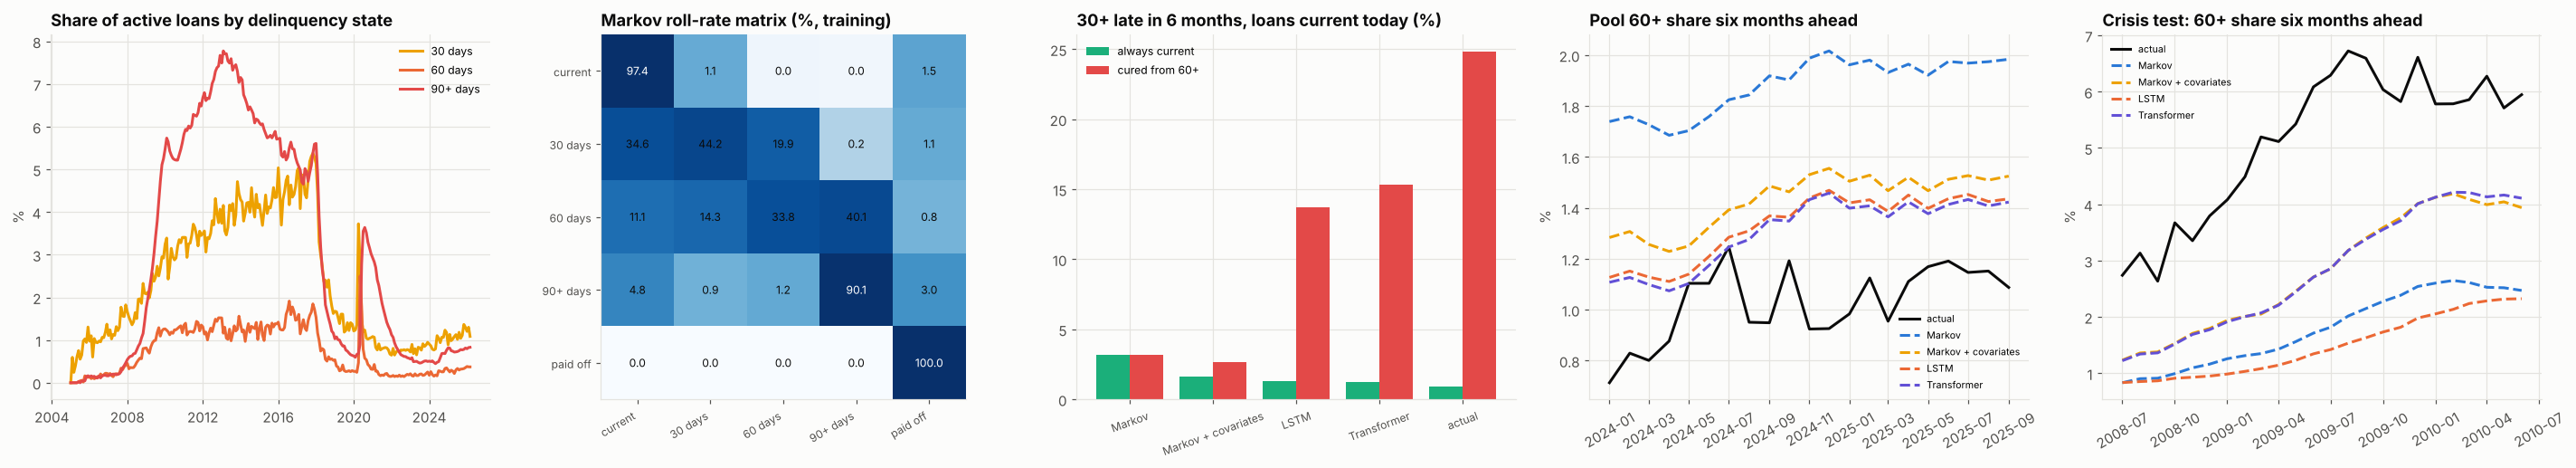

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(26, 4.8))
ax = axes[0]
dates = pd.to_datetime(share.index.astype(str), format="%Y%m")
for k, col in zip([1, 2, 3], [PALETTE[3], PALETTE[1], PALETTE[7]]):
    ax.plot(dates, share[k] * 100, color=col, label=STATES[k])
ax.set_title("Share of active loans by delinquency state")
ax.set_ylabel("%")
ax.legend(fontsize=8)
ax = axes[1]
im = ax.imshow(np.log10(P1 * 100 + 0.01), cmap="Blues")
for i in range(5):
    for j in range(5):
        ax.text(
            j,
            i,
            f"{P1[i, j] * 100:.1f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if P1[i, j] > 0.5 else INK,
        )
ax.set_xticks(range(5), STATES, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(5), STATES, fontsize=8)
ax.grid(False)
ax.set_title("Markov roll-rate matrix (%, training)")
ax = axes[2]
g = hist_tab[
    [c for c in hist_tab.columns if c.endswith("t+6 %")]
    + ["actual: 30+ late in 6 months %"]
].T
xi = np.arange(len(g))
ax.bar(xi - 0.2, g.iloc[:, 0], 0.4, color=PALETTE[2], label="always current")
ax.bar(xi + 0.2, g.iloc[:, 1], 0.4, color=PALETTE[7], label="cured from 60+")
ax.set_xticks(
    xi,
    [
        c.replace(" t+6 %", "").replace(
            "actual: 30+ late in 6 months %", "actual"
        )
        for c in g.index
    ],
    rotation=20,
    fontsize=8,
)
ax.set_title("30+ late in 6 months, loans current today (%)")
ax.legend(fontsize=8)
ax = axes[3]
xs = pd.to_datetime(pool_fc.index.astype(str), format="%Y%m")
ax.plot(xs, pool_fc["actual 60+ %"], color=INK, lw=2, label="actual")
for m, col in zip(pred, [PALETTE[0], PALETTE[3], PALETTE[1], PALETTE[6]]):
    ax.plot(xs, pool_fc[f"{m} 60+ %"], color=col, ls="--", label=m)
ax.set_title("Pool 60+ share six months ahead")
ax.set_ylabel("%")
ax.legend(fontsize=7)
ax.tick_params(axis="x", rotation=30)
ax = axes[4]
xs = pd.to_datetime(crisis_path.index.astype(str), format="%Y%m")
ax.plot(xs, crisis_path["actual"], color=INK, lw=2, label="actual")
for m, col in zip(pred_c, [PALETTE[0], PALETTE[3], PALETTE[1], PALETTE[6]]):
    ax.plot(xs, crisis_path[m], color=col, ls="--", label=m)
ax.set_title("Crisis test: 60+ share six months ahead")
ax.set_ylabel("%")
ax.legend(fontsize=7)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
save_fig(fig, "01_states_rollrates_history_pool")
plt.show()

## 9. Reading the results and limitations

83,218 loans (one in six: Fannie Mae 2005–08 and Freddie Mac 2018–23 vintages), 753,817 anchors; training anchors up to June 2023, main test on January 2024 – September 2025, crisis test on July 2008 – June 2010.

**Two delinquency regimes.** Among active loans, 90+ day delinquency rose from 0.2% at the end of 2006 to 5.3% in 2009 and 7.7% in 2012, as the crisis loans that did not prepay sank deeper into arrears. In the recent loans it peaked at 3% in 2020 (forbearance) and is 0.8% today. The pooled roll-rate matrix carries both: each month 97.4% of current loans stay current and 1.1% roll to 30 days; 44% of 30-day loans stay and 35% cure; of 60-day loans 40% roll to 90+ and 11% cure; and 90+ is very sticky (90% stay, 5% cure).

**History matters a lot, and a first-order Markov chain cannot see it.** Among loans that are current today, those that were 60+ days late at some point in the last year are **25%** likely to be 30+ days late in six months, against **0.9%** for loans that were always current: 26 times more. The Markov chain gives both groups 3.1%. The logit with covariates moves the cured group only to 2.7%; the Transformer (15.3%) and the LSTM (13.7%) recover most of the gap because they read the path.

**The sequence models now win on the pool as well.** In the main test the LSTM has the lowest log-loss at one month (0.082 against 0.094 for Markov) and six months (0.248 against 0.282) and the best accuracy for 30-day loans (56% against 42%). The 60+ share six months ahead is forecast with a mean absolute error of 0.28 points by the Transformer, 0.30 by the LSTM, 0.41 by the logit and 0.86 by Markov. With the crisis years in the training data, the Markov matrix is too pessimistic for today's book (it predicts about 1.9% against 1.0%), while the sequence models condition on each loan's clean recent history.

**No model foresaw the crisis.** Trained on anchors up to December 2007 and asked for July 2008 – June 2010, every model under-predicted. The realised share of loans 60+ days late six months later averaged **5.1%**; the logit and the Transformer forecast 2.7%, Markov 1.7% and the LSTM 1.4%. The transitions changed: 24% of 30-day loans rolled to 60+ days (models: 5–16%) and only 9% of 60-day loans cured (models: 15–19%; the LSTM, trained on very few delinquent pre-crisis sequences, forecast 75%). Learned from a calm period, any roll-rate model, sequence or not, describes the calm period. Surveillance needs macro inputs or stressed matrices on top.

- **For practice:** use the Markov matrix as the transparent benchmark, a sequence model (or at least explicit history features: months since last delinquency, worst status in 12 months) wherever loan-level ranking matters, and validate on segments and on a stress period, not just on the pool total.

**Limitations**

- Clean anchors are sub-sampled (8%) with weights; metrics are weighted back to the population, but neural training on reweighted data is noisier than on the full set.
- The training data mix two agencies and two periods, including the 2020–21 forbearance episode, which distorts 60+ and 90+ cure rates.
- No macro inputs: delinquency transitions move with unemployment and house prices, which the crisis test shows matters most.

In [11]:
pd.DataFrame(P1, index=STATES, columns=STATES).to_csv(
    OUT_DIR / "markov_roll_rate_matrix.csv"
)
evaluation.to_csv(OUT_DIR / "out_of_time_evaluation.csv")
crisis_eval.to_csv(OUT_DIR / "crisis_test_2008_2010.csv")
crisis_path.to_csv(OUT_DIR / "crisis_test_pool_path.csv")
hist_tab.to_csv(OUT_DIR / "path_dependence_test.csv")
pool_fc.to_csv(OUT_DIR / "pool_forecast_60plus.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_states_rollrates_history_pool.png, crisis_test_2008_2010.csv, crisis_test_pool_path.csv, markov_roll_rate_matrix.csv, out_of_time_evaluation.csv, path_dependence_test.csv, pool_forecast_60plus.csv


## References

### Finance and regulation

- Grimshaw, S. D., & Alexander, W. P. (2011). Markov chain models for delinquency: Transition matrix estimation and forecasting. *Applied Stochastic Models in Business and Industry, 27*(3), 267–279. https://doi.org/10.1002/asmb.827
- Thomas, L. C., Crook, J., & Edelman, D. (2017). *Credit scoring and its applications* (2nd ed.). SIAM. https://doi.org/10.1137/1.9781611974560
- Sirignano, J., Sadhwani, A., & Giesecke, K. (2021). Deep learning for mortgage risk. *Journal of Financial Econometrics, 19*(2), 313–368. https://doi.org/10.1093/jjfinec/nbaa025
- Jarrow, R. A., Lando, D., & Turnbull, S. M. (1997). A Markov model for the term structure of credit risk spreads. *The Review of Financial Studies, 10*(2), 481–523. https://doi.org/10.1093/rfs/10.2.481
- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data

### Machine learning and deep learning

- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1706.03762
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703